# Multi-Layer Perceptron (MLP)

This model is a neural network written from scratch in plain Python lists. It predicts the policy class of each *province* (`INCREASE = 1`, `RETAIN = 0`, `DECREASE = -1`) from its standardized features.

Architecture: **input → hidden (ReLU) → output (softmax, 3 classes)**, trained with batch gradient descent.

In [1]:
%pip install numpy

Note: you may need to restart the kernel to use updated packages.


In [2]:
import csv
import random
from collections import Counter
from statistics import mean, stdev
from contextlib import redirect_stdout
from io import StringIO
from pathlib import Path
from os import path

from methods.read_data import createMatrix, printMatrix
from methods.normalize_data import standardizeData, coalesceData
from models.mlp import gradient_descent, make_predictions, get_accuracy
from evaluation.holdout_validation import holdout_split, holdout_validation
from evaluation.kfold_cross_validation import kFoldSplit, crossValidation, accuracy
from evaluation.conf_matrix import evaluate

### Step 1: Create the Dataset from the `PROJECT_DATASET` folder
- This will create a matrix with 12 fields/attributes and 87 provinces

In [3]:
data_set_dir = path.join(path.abspath("."), "PROJECT_DATASET")          # Get the path to the dataset folder
provinces, fields, matrix = createMatrix(Path(data_set_dir))            # Create the matrix from the dataset
printMatrix(provinces, fields, matrix)                                  # Print the matrix with all of the provinces and fields

87 provinces x 12 fields
showing fields 0 to 11 

  [0] Table_2 | Poverty Incidence among Population (%) 2023
  [1] Table_2 | Poverty Incidence among Population (%) 2021
  [2] Table_2 | Poverty Incidence among Population (%) 2018
  [3] Table_12 | Estimate (%) 2023
  [4] Table_6 | Estimate ('000) 2023
  [5] Table_2 | Annual Per Capita Poverty Threshold (in PhP) 2023
  [6] Total Family Size | Average Income
  [7] Total Family Size | Average Expenditure
  [8] Table_7 | Information and Communication
  [9] DERIVED | Change in poverty incidence 2021 to 2023 (percentage points)
  [10] DERIVED | Change in poverty incidence 2018 to 2023 (percentage points)
  [11] DERIVED | Income inequality (top 10% share / bottom 40% share)

Province                       [0]         [1]         [2]         [3]         [4]         [5]         [6]         [7]         [8]         [9]        [10]        [11]
NCR 1st District               2.4         1.7         3.0         0.1       46.54     37711.0      482.79

### Step 2: Cleanup the data
- Coalesce missing values to 0, then standardize it using Z-score Scaling
- `featuresList` is a list of feature vectors, in the same order as `provinces`

In [4]:
# Coalesce NA values to 0, then standardize it.
cleaned_data = standardizeData(coalesceData(matrix))
featuresList = [list(row) for row in cleaned_data]      # Plain lists, so the label can be appended later

print(f"{len(provinces)} provinces, {len(featuresList[0])} features each")

87 provinces, 12 features each


### Step 3: Load the labels from `province_policy_results.csv`
- Unlike k-means, the MLP is *supervised*, so every province needs its true label
- Read the actual class of each province from the tagged dataset, the same way as in the k-means notebook
- The tagged dataset is created by `methods/label_data.py` from the policies in the Policy for Labeling Data section of the project document
- The class is converted to `INCREASE = 1`, `RETAIN = 0`, `DECREASE = -1`
- `labelList` follows the order of `provinces`, so `featuresList[i]` and `labelList[i]` belong to the same province

In [5]:
# Read the actual class of each province from the tagged dataset
tagged_dir = path.join(data_set_dir, "province_policy_results.csv")    # Get the path to the tagged dataset
with open(tagged_dir, newline="", encoding="utf-8-sig") as file:
  actual_classes = {row["Province"]: row["Class"] for row in csv.DictReader(file)}

# Convert the class of each province to a number, in the same order as provinces
CLASS_TO_LABEL = {"INCREASE": 1, "RETAIN": 0, "DECREASE": -1}
labelList = [CLASS_TO_LABEL[actual_classes[id]] for id in provinces]

print("Label counts:", Counter(labelList))

Label counts: Counter({1: 46, 0: 31, -1: 10})


### Step 4: Map the labels to class indices
- The output layer has 3 neurons (one per class), so the network works with the indices `0, 1, 2`, not `-1, 0, 1`
- `CLASSES` is the single source of truth: `index[label]` going in, `CLASSES[i]` coming out
- A raw `-1` would silently land in the last column through negative indexing, so always map first

In [6]:
CLASSES = (-1, 0, 1)                                          # Column order of the output layer
index = {label: i for i, label in enumerate(CLASSES)}         # {-1: 0, 0: 1, 1: 2}
print("Label -> index:", index)

Label -> index: {-1: 0, 0: 1, 1: 2}


### Step 5: Split the provinces into a training set and a testing set
- 80% of the provinces are used for training and the remaining 20% for testing
- The training rows carry the true label as the last element, so it is stripped off before training

In [7]:
training_list, testing_rows, test_labels, test_indices = holdout_split(featuresList, labelList, 0.8)

X_train = [row[:-1] for row in training_list]                 # Features only
Y_train = [index[row[-1]] for row in training_list]           # Labels as class indices
print(f"Training provinces: {len(X_train)}, Testing provinces: {len(testing_rows)}")

Training provinces: 70, Testing provinces: 17


### Step 6: Build the model wrapper and the grid search
- `make_mlp_model(alpha, iterations, hiddenNum)` returns a `model(testing_rows, training_list)` function, the same shape that `crossValidation` and `holdout_validation` expect (like `kmeans_model` in the k-means notebook)
- The training rows carry the label as the last element, the testing rows have no label, and every testing row is returned with its predicted label appended
- `grid_search` tries **every combination** of the hyperparameters in the grid, scores each one with k-fold cross validation, and returns the best one
- The grid search only sees the training rows it is given, so the testing provinces never influence which hyperparameters are picked
- `macro_f1` is also reported because the classes are imbalanced (only 10 `DECREASE` provinces), so accuracy alone can hide a class that is never predicted

In [8]:
from itertools import product

def make_mlp_model(alpha, iterations, hiddenNum):
  def model(testing_rows, training_list):
    X = [row[:-1] for row in training_list]                   # Features only
    Y = [index[row[-1]] for row in training_list]             # Labels as class indices

    random.seed(1)                                            # Same starting weights every run
    with redirect_stdout(StringIO()):                         # Hide the training progress
      w1, b1, w2, b2 = gradient_descent(X, Y, alpha=alpha, iterations=iterations, hiddenNum=hiddenNum, outputNum=3)

    predicted = make_predictions(testing_rows, w1, b1, w2, b2)
    return [testing_rows[i] + [CLASSES[predicted[i]]] for i in range(len(testing_rows))]
  return model

def macro_f1(results):
  # Average of the one vs. rest F1 score of every class, each result is (index, actual, predicted, fold)
  scores = []
  for c in CLASSES:
    tp = sum(r[1] == c and r[2] == c for r in results)
    fp = sum(r[1] != c and r[2] == c for r in results)
    fn = sum(r[1] == c and r[2] != c for r in results)
    scores.append(2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0.0)
  return sum(scores) / len(scores)

def grid_search(features, labels, grid, folds=5, scoring="accuracy"):
  # Try every combination in the grid, the first best combination wins a tie (the grid is ordered from cheapest to costliest)
  fold_list = kFoldSplit(len(features), folds)
  tie_breaker = "macro_f1" if scoring == "accuracy" else "accuracy"
  rows = []
  for values in product(*grid.values()):
    params = dict(zip(grid.keys(), values))
    results = crossValidation(features, labels, fold_list, make_mlp_model(**params))
    rows.append({"params": params, "accuracy": accuracy(results), "macro_f1": macro_f1(results)})
  best = max(rows, key=lambda r: (r[scoring], r[tie_breaker]))
  return best, rows

### Step 7: Run the grid search on the training set only
- The grid has 3 x 3 x 3 = 27 combinations, each one is scored with 5-fold cross validation on the 70 training provinces (135 networks in total, so this cell takes a while)
- `scoring` can be changed to `"macro_f1"` if the minority class `DECREASE` should matter more than the overall accuracy
- The testing provinces from Step 5 are not touched here

In [9]:
param_grid = {
  "hiddenNum":  [5, 10, 20, 60, 65, 70],            # Neurons in the hidden layer
  "alpha":      [0.05, 0.1, 0.5],       # Learning rate
  "iterations": [50, 100, 200],         # Gradient descent steps
}

train_features = [row[:-1] for row in training_list]      # Training features only, no label
train_labels = [row[-1] for row in training_list]         # Training labels as -1 / 0 / 1

best, grid_rows = grid_search(train_features, train_labels, param_grid, folds=5, scoring="accuracy")

print(f"{'hiddenNum':>9} {'alpha':>6} {'iterations':>10} {'Accuracy':>9} {'Macro F1':>9}")
for r in sorted(grid_rows, key=lambda r: (r['accuracy'], r['macro_f1']), reverse=True):
  p = r["params"]
  mark = "  <- best" if r is best else ""
  print(f"{p['hiddenNum']:>9} {p['alpha']:>6} {p['iterations']:>10} {r['accuracy']:>9.2%} {r['macro_f1']:>9.4f}{mark}")

best_params = best["params"]
print(f"\nBest hyperparameters: {best_params}")

hiddenNum  alpha iterations  Accuracy  Macro F1
       20   0.05        200    75.71%    0.7265  <- best
       20    0.1        100    75.71%    0.7265
       70   0.05        200    75.71%    0.6801
       70    0.1        100    75.71%    0.6801
       10    0.1        200    75.71%    0.6504
       10   0.05        200    75.71%    0.5235
       10    0.1        100    75.71%    0.5235
       10   0.05        100    75.71%    0.5217
       10    0.1         50    75.71%    0.5217
       20    0.1        200    74.29%    0.7147
       20    0.5         50    74.29%    0.7147
       65    0.5        100    74.29%    0.6809
        5    0.5        200    74.29%    0.6682
       60   0.05        100    74.29%    0.6329
       60    0.1         50    74.29%    0.6329
       10    0.5         50    74.29%    0.6305
       70    0.5         50    72.86%    0.6752
       70    0.1        200    72.86%    0.6561
       65   0.05         50    72.86%    0.6500
       65   0.05        100    

### Step 8: Predict the provinces in the testing set with the best hyperparameters
- A new network is trained on all of the training provinces using `best_params`, then it predicts the testing provinces
- The untuned network from before (`hiddenNum=10, alpha=0.1, iterations=20`) is run on the same testing provinces for comparison

In [10]:
tuned_output = make_mlp_model(**best_params)(testing_rows, training_list)
predictions = [row[-1] for row in tuned_output]

print(f"{'Province':<25} {'True':>5} {'Predicted':>10}")
for i, true, pred in zip(test_indices, test_labels, predictions):
    print(f"{provinces[i]:<25} {true:>5} {pred:>10}")

correct = sum(t == p for t, p in zip(test_labels, predictions))
print(f"\nTuned test accuracy: {correct}/{len(test_labels)} = {correct / len(test_labels):.2%}")

# Untuned baseline on the same testing provinces
baseline_output = make_mlp_model(alpha=0.1, iterations=20, hiddenNum=10)(testing_rows, training_list)
baseline_predictions = [row[-1] for row in baseline_output]
baseline_correct = sum(t == p for t, p in zip(test_labels, baseline_predictions))
print(f"Untuned test accuracy: {baseline_correct}/{len(test_labels)} = {baseline_correct / len(test_labels):.2%}")

Province                   True  Predicted
Dinagat Islands               1          1
NCR 1st District             -1         -1
Northern Samar                1          1
Siquijor                     -1          0
NCR 4th District             -1         -1
Bukidnon                      1          1
La Union                      0          0
Batangas                     -1          0
Negros Oriental               0          1
Zamboanga Sibugay             1          1
Samar                         1          1
Camiguin                      0          1
Cagayan                       0          0
Occidental Mindoro            1          1
Kalinga                       0          0
Cotabato                      1          1
Nueva Vizcaya                 0          0

Tuned test accuracy: 13/17 = 76.47%
Untuned test accuracy: 11/17 = 64.71%


### Step 9: Confusion Matrix of the Holdout Validation
- Compare the predicted class with the actual class of the testing provinces
- Compute the Recall, Precision, F1 Score and Accuracy for each class (one vs. rest)

In [11]:
# Calculate and display the confusion matrix and the performance metrics for each class
holdout_metrics = evaluate(test_labels, predictions)

Confusion Matrix (Positive class: -1)
                      Predicted    
                  Positive Negative
Actual    Positive       2        2
          Negative       0       13
Recall:    0.5000
Precision: 1.0000
F1 Score:  0.6667
Accuracy:  0.8824

Confusion Matrix (Positive class: 0)
                      Predicted    
                  Positive Negative
Actual    Positive       4        2
          Negative       2        9
Recall:    0.6667
Precision: 0.6667
F1 Score:  0.6667
Accuracy:  0.7647

Confusion Matrix (Positive class: 1)
                      Predicted    
                  Positive Negative
Actual    Positive       7        0
          Negative       2        8
Recall:    1.0000
Precision: 0.7778
F1 Score:  0.8750
Accuracy:  0.8824



### Step 9.1: Visualize the training points of the holdout validation in 3D
- The network uses all 12 fields, but a plot can only show three, so three selected features are used as the x, y and z dimensions (the same ones as in the k-means and k-nearest neighbors notebooks)
- Change `selected_features` to the indexes of the fields to plot (see the field list in Step 1)
- The large points are the training provinces (80%), and their color is their true class (red for INCREASE, blue for DECREASE, gray for RETAIN)
- The small points are the testing provinces (20%), and their color is the class predicted by the tuned network in Step 8

/tmp/ipykernel_35989/1778250757.py:32: UserWarning: You passed an edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter([x_coords[i] for i in training],


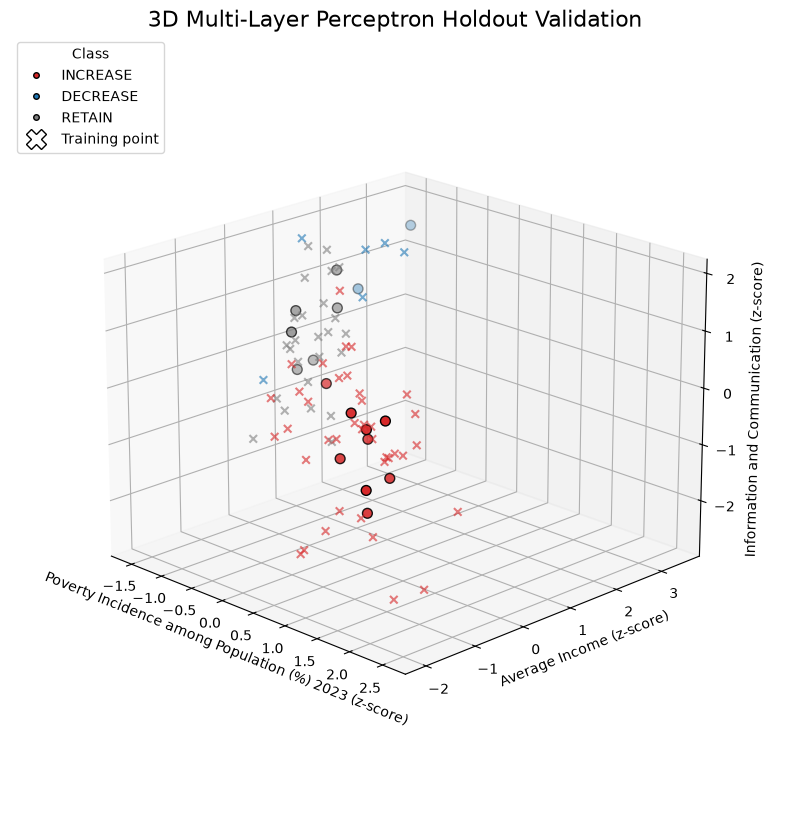

In [17]:
import matplotlib.pyplot as plt

# Indexes of the three fields to use as the x, y and z dimensions (see the field list in Step 1)
selected_features = [0, 6, 8]     # Poverty Incidence 2023, Average Income, Information and Communication

# Color of each class, and the name of each class value (1 = INCREASE, 0 = RETAIN, -1 = DECREASE)
class_colors = {"INCREASE": "tab:red", "DECREASE": "tab:blue", "RETAIN": "tab:gray"}
class_names = {value: name for name, value in CLASS_TO_LABEL.items()}

# Create the 3D Matplotlib Plot
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(projection='3d')  # Enable 3D projection

# Extract the coordinates of each province from the selected features
x_coords = [p[selected_features[0]] for p in featuresList]
y_coords = [p[selected_features[1]] for p in featuresList]
z_coords = [p[selected_features[2]] for p in featuresList]

# test_indices are the testing provinces of the split in Step 5, in the same order as predictions
# The provinces that are not in test_indices are the training provinces
testing = test_indices
training = [i for i in range(len(provinces)) if i not in testing]

# Testing points, colored by the class predicted by the tuned network
ax.scatter([x_coords[i] for i in testing],
           [y_coords[i] for i in testing],
           [z_coords[i] for i in testing],
           c=[class_colors[class_names[pred]] for pred in predictions],
           s=50, alpha=1, edgecolor='k')

# Highlight the training points, colored by their true class
ax.scatter([x_coords[i] for i in training],
           [y_coords[i] for i in training],
           [z_coords[i] for i in training],
           c=[class_colors[class_names[labelList[i]]] for i in training],
           marker='x', s=30, alpha=0.6, edgecolor='k', linewidth=1.5, depthshade=False)

# Formatting and Titles
# The values are standardized (z-score), since those are the values the network was trained on
ax.set_title("3D Multi-Layer Perceptron Holdout Validation", fontsize=16)
ax.set_xlabel(fields[selected_features[0]].split(" | ")[-1] + " (z-score)")
ax.set_ylabel(fields[selected_features[1]].split(" | ")[-1] + " (z-score)")
ax.set_zlabel(fields[selected_features[2]].split(" | ")[-1] + " (z-score)")

# Legend with one entry per class, and one for the highlighted marker
handles = [plt.Line2D([], [], marker='.', linestyle='', color=color, markeredgecolor='k', markersize=8) for color in class_colors.values()]
handles.append(plt.Line2D([], [], marker='X', linestyle='', color='w', markeredgecolor='k', markersize=14))
ax.legend(handles, list(class_colors.keys()) + ["Training point"], title="Class", loc="upper left")
ax.set_box_aspect(None, zoom=0.85)     # Zoom out a bit so the z-axis label is not cut off

# Adjust the viewing angle (elevation, azimuth)
ax.view_init(elev=20, azim=-45)

plt.show()

### Step 10: K-Fold Cross Validation with the best hyperparameters
- The provinces are split into 5 folds, each fold is the testing set once and the other folds are the training set
- The hyperparameters were picked using only the 70 training provinces of Step 5, but the testing folds here also contain some of those provinces, so this accuracy is slightly optimistic
- Every province is predicted exactly once, so the accuracy uses all of the provinces

In [13]:
folds = 5
foldList = kFoldSplit(len(featuresList), folds)

# Each result is a tuple (province index, true label, predicted label, fold)
kfold_results = crossValidation(featuresList, labelList, foldList, make_mlp_model(**best_params))

fold_accuracies = []
for f in range(folds):
    fold_results = [result for result in kfold_results if result[3] == f + 1]
    fold_accuracies.append(accuracy(fold_results))
    correct = sum(result[1] == result[2] for result in fold_results)
    print(f"Fold {f + 1}: {correct}/{len(fold_results)} = {fold_accuracies[-1]:.2%}")

correct = sum(result[1] == result[2] for result in kfold_results)
print(f"\nK-fold accuracy: {correct}/{len(kfold_results)} = {accuracy(kfold_results):.2%}")
print(f"Average of the folds: {mean(fold_accuracies):.2%}, standard deviation: {stdev(fold_accuracies):.2%}")

Fold 1: 15/18 = 83.33%
Fold 2: 13/18 = 72.22%
Fold 3: 15/17 = 88.24%
Fold 4: 10/17 = 58.82%
Fold 5: 14/17 = 82.35%

K-fold accuracy: 67/87 = 77.01%
Average of the folds: 76.99%, standard deviation: 11.71%


### Step 11: Confusion Matrix of the K-Fold Cross Validation
- The predictions from the k-fold cross validation are used, so the confusion matrix counts all of the provinces

In [14]:
actual = [result[1] for result in kfold_results]              # Actual class from the tagged dataset
predicted = [result[2] for result in kfold_results]           # Predicted class from the network

# Calculate and display the confusion matrix and the performance metrics for each class
kfold_metrics = evaluate(actual, predicted)

Confusion Matrix (Positive class: -1)
                      Predicted    
                  Positive Negative
Actual    Positive       6        4
          Negative       2       75
Recall:    0.6000
Precision: 0.7500
F1 Score:  0.6667
Accuracy:  0.9310

Confusion Matrix (Positive class: 0)
                      Predicted    
                  Positive Negative
Actual    Positive      22        9
          Negative      11       45
Recall:    0.7097
Precision: 0.6667
F1 Score:  0.6875
Accuracy:  0.7701

Confusion Matrix (Positive class: 1)
                      Predicted    
                  Positive Negative
Actual    Positive      39        7
          Negative       7       34
Recall:    0.8478
Precision: 0.8478
F1 Score:  0.8478
Accuracy:  0.8391

